In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import Bounds, minimize
from scipy.stats import cauchy, expon, chi2

In [3]:
#CONSTANTS
E0 = 205
G = 28
Eb = 100

In [9]:
data_path = "data/Project3_Set2.txt"
df = pd.read_csv(data_path, header=None).astype(float)
E = np.array(df)

In [7]:
N_photons = len(df)
print(f"Number of total events : {N_photons}")

Number of total events : 377


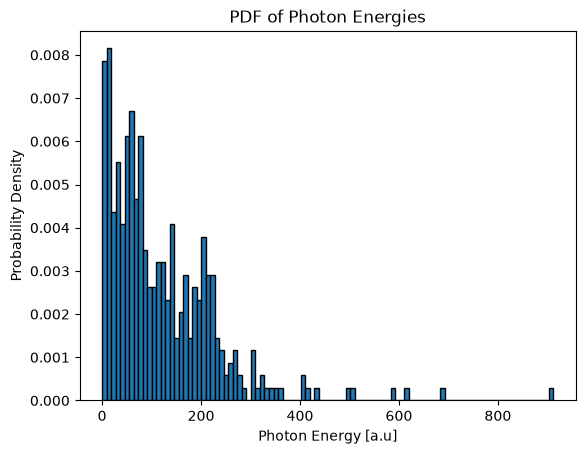

In [14]:
plt.hist(E,bins=100,edgecolor="k",density=True)
plt.xlabel("Photon Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energies")
plt.show()

In [15]:
def signal(ns, E) -> np.array:
    return (ns/N_photons)*cauchy.pdf(E, loc=E0, scale=G)

def background(nb, E) -> np.array:
    return (nb/N_photons)*expon.pdf(E, loc=0, scale=Eb)

def complete_pdf(x, E):
    ns, nb = x
    return signal(ns,E) + background(nb,E)

def loglikelihood(x, E) -> float:
    return -2*np.sum(np.log(complete_pdf(x,E)), axis=0)

def total_photons_constraint(x):
    return x[0] + x[1] - N_photons

In [16]:
ns_bound = [0,N_photons]
nb_bound = [0,N_photons]

ns_init = N_photons/2
nb_init = N_photons/2
init_vals = [ns_init, nb_init]

bound_arr = [ns_bound,nb_bound]
cons = {'type':'eq', 'fun': total_photons_constraint}

In [23]:
min_params = minimize(loglikelihood, x0=init_vals, args=E ,method="SLSQP", bounds=bound_arr, constraints=cons)
ns, nb = min_params.x
ns = round(ns)
nb = round(nb)
print(f"N_signal: {ns} \nN_background:{nb}")

N_signal: 54 
N_background:323


In [25]:
Energy_centers = np.linspace(0,np.max(E),N_photons)
pred_total = complete_pdf(min_params.x,Energy_centers)
pred_signal = signal(ns,Energy_centers)
pred_background = background(nb, Energy_centers)

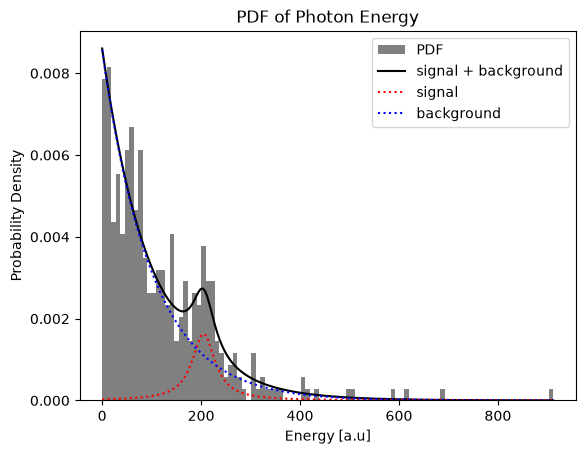

In [26]:
plt.hist(E, bins=100, density=True, label="PDF", color="grey")
plt.plot(Energy_centers, pred_total,color="black", label="signal + background")
plt.plot(Energy_centers, pred_signal,linestyle="dotted",color="red", label="signal")
plt.plot(Energy_centers, pred_background,linestyle="dotted" ,color="blue", label="background")
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energy")
plt.legend()
plt.show()